# Extraction des courbes HPFC

**Utilisation** : exécute tout le notebook (*Run All*), puis réponds aux questions qui
s'affichent dans la boîte de saisie. Aucune cellule à modifier.

Le notebook :
0. se prépare seul au premier lancement (librairie d'export Excel, exclusion des exports de Git) ;
1. récupère sur GitHub les dernières courbes archivées par le workflow quotidien (`git pull`) ;
2. charge la ou les courbes demandées ;
3. les filtre et les agrège selon tes critères ;
4. affiche le résultat, un graphique, et l'exporte si tu le demandes.

Règle habituelle : aucune donnée n'est inventée. Une date de pricing absente de l'archive,
une synchronisation GitHub impossible ou une période vide arrêtent le notebook avec un
message explicite.

## 1. Dépôt et synchronisation avec GitHub

In [19]:
import subprocess
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

from hpfc import archive
from hpfc.calendar import build_calendar
from hpfc.config import load_config
from marketdata import DataNotFoundError

MARKET = "FR"


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Remonte les dossiers jusqu'au pyproject.toml du projet power-hpfc."""
    for d in [start, *start.parents]:
        f = d / "pyproject.toml"
        if f.exists() and 'name = "power-hpfc"' in f.read_text(encoding="utf-8"):
            return d
    raise FileNotFoundError("dépôt power-hpfc introuvable : ouvre ce notebook depuis le dossier du projet")


def git(*args: str) -> str:
    r = subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args)} a échoué :\n{r.stderr.strip()}")
    return r.stdout.strip()


def ask(question: str, default: str, parse, choices: str = ""):
    """Pose une question avec les réponses possibles ; Entrée = valeur par défaut ;
    redemande tant que la réponse est invalide."""
    prompt = f"{question} — {choices} — Entrée = {default}" if choices else f"{question} — Entrée = {default}"
    while True:
        raw = input(prompt + " : ").strip()
        try:
            value = parse(raw if raw else default)
            print(f"{question} : {raw if raw else default}")
            return value
        except (ValueError, DataNotFoundError) as exc:
            print(f"  Réponse invalide ({exc}), recommence.")


REPO = find_repo_root()
DATA = REPO / "data"
cfg = load_config(MARKET)

# Préparation automatique : librairie d'export Excel et exclusion des exports de Git
import importlib.util
import sys

if importlib.util.find_spec("openpyxl") is None:
    print("Installation d'openpyxl (export Excel)...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "openpyxl"], check=True)
gitignore = REPO / ".gitignore"
if "exports/" not in gitignore.read_text(encoding="utf-8").split():
    with gitignore.open("a", encoding="utf-8") as f:
        f.write("\n# Extractions locales\nexports/\n")
    print("exports/ ajouté au .gitignore (les fichiers exportés ne partent pas sur GitHub)")

def parse_yes_no(r: str) -> bool:
    answers = {"o": True, "oui": True, "n": False, "non": False}
    if r.lower() not in answers:
        raise ValueError("répondre o ou n")
    return answers[r.lower()]


SYNC_GITHUB = ask("Récupérer les dernières courbes sur GitHub ?", "o", parse_yes_no, "o (oui) / n (non)")
before = archive.list_curves(MARKET, DATA)
if SYNC_GITHUB:
    if git("status", "--porcelain", "--", "data"):
        raise RuntimeError("des fichiers de data/ sont modifiés localement : les committer ou les annuler "
                           "avant de synchroniser (sinon la mise à jour risquerait de les écraser)")
    git("fetch", "--quiet")
    behind = int(git("rev-list", "--count", "HEAD..@{u}"))
    if behind:
        git("pull", "--ff-only", "--quiet")
    status = f"{behind} mise(s) à jour récupérée(s) depuis GitHub" if behind else "déjà à jour avec GitHub"
else:
    status = "synchronisation désactivée : les courbes peuvent ne pas être les dernières"
after = archive.list_curves(MARKET, DATA)
if not after:
    raise DataNotFoundError(f"aucune courbe {MARKET} archivée dans {DATA}")

print(f"Dépôt : {REPO}")
print(f"GitHub : {status}")
print(f"Courbes archivées : {len(after)} (du {after[0]} au {after[-1]})"
      + (f" | nouvelles : {[str(d) for d in sorted(set(after) - set(before))]}" if set(after) - set(before) else ""))

Récupérer les dernières courbes sur GitHub ? : n
Dépôt : /Users/clem/Documents/2-Coding/python/HPFC/power-hpfc
GitHub : synchronisation désactivée : les courbes peuvent ne pas être les dernières
Courbes archivées : 33 (du 2026-08-24 au 2026-10-07)


## 2. Moteur d'extraction

In [20]:
GRANULARITIES = {"hour": None, "day": "D", "week": "W-SUN", "month": "M", "quarter": "Q", "year": "Y"}
PROFILES = ("base", "peak", "offpeak")


def _d(x) -> date:
    return x if isinstance(x, date) else date.fromisoformat(str(x))


def resolve_pricing(market: str, pricing, root: Path) -> list[date]:
    """Traduit le critère PRICING en liste de dates de pricing archivées."""
    available = archive.list_curves(market, root)
    if pricing == "latest":
        return [available[-1]]
    if isinstance(pricing, tuple):
        lo, hi = _d(pricing[0]), _d(pricing[1])
        found = [d for d in available if lo <= d <= hi]
        if not found:
            raise DataNotFoundError(f"aucune courbe entre le {lo} et le {hi}")
        return found
    wanted = [_d(p) for p in (pricing if isinstance(pricing, list) else [pricing])]
    missing = [d for d in wanted if d not in available]
    if missing:
        near = [d for d in available if abs((d - missing[0]).days) <= 7]
        raise DataNotFoundError(f"courbe(s) absente(s) de l'archive : {[str(d) for d in missing]}. "
                                f"Dates archivées proches : {[str(d) for d in near]}")
    return sorted(wanted)


def aggregate(curve: pd.DataFrame, granularity: str, profile: str, tz: str,
              start: date | None, end: date | None) -> pd.DataFrame:
    """Filtre la livraison et le profil, puis agrège (moyenne horaire) à la granularité voulue."""
    if granularity not in GRANULARITIES or profile not in PROFILES or tz not in ("local", "utc"):
        raise ValueError(f"critère invalide : {granularity!r}, {profile!r}, {tz!r}")
    local = pd.to_datetime(curve["local"])
    day = local.dt.date
    mask = pd.Series(True, index=curve.index)
    if start is not None:
        mask &= day >= start
    if end is not None:
        mask &= day <= end
    if profile == "peak":
        mask &= curve["is_peak"]
    elif profile == "offpeak":
        mask &= ~curve["is_peak"]
    sub = curve[mask]
    if sub.empty:
        raise DataNotFoundError("aucune heure ne correspond aux critères (période ou profil)")

    if granularity == "hour":
        idx = local[mask] if tz == "local" else sub.index
        return pd.DataFrame({"price": sub["price"].to_numpy(), "hours": 1}, index=pd.Index(idx, name="hour"))

    freq = GRANULARITIES[granularity]
    period = local[mask].dt.tz_localize(None).dt.to_period(freq).dt.start_time
    out = sub.assign(period=period.to_numpy()).groupby("period").agg(price=("price", "mean"),
                                                                     hours=("price", "size"))
    out.index.name = granularity

    # Période complète ? On compare au nombre d'heures du profil dans la période calendaire entière
    p0 = out.index.min().date()
    p1 = pd.Period(out.index.max(), freq).end_time.date()
    full = build_calendar(cfg, p0, p1)
    fmask = full["is_peak"] if profile == "peak" else (~full["is_peak"] if profile == "offpeak"
                                                       else pd.Series(True, index=full.index))
    fper = pd.to_datetime(full.loc[fmask, "local"]).dt.tz_localize(None).dt.to_period(freq).dt.start_time
    expected = fper.value_counts()
    out["complete"] = out["hours"].to_numpy() == expected.reindex(out.index).to_numpy()
    return out


def extract(market: str, pricing, granularity: str = "hour", profile: str = "base", tz: str = "local",
            start=None, end=None, root: Path = DATA) -> tuple[pd.DataFrame, list[date]]:
    """Une date de pricing : colonnes price et hours. Plusieurs : une colonne de prix par date."""
    dates = resolve_pricing(market, pricing, root)
    start, end = (_d(start) if start else None), (_d(end) if end else None)
    frames = {d: aggregate(archive.load_curve(market, d, root), granularity, profile, tz, start, end)
              for d in dates}
    if len(dates) == 1:
        return frames[dates[0]], dates
    wide = pd.DataFrame({str(d): f["price"] for d, f in frames.items()})
    wide.columns.name = "pricing_date"
    if granularity != "hour":
        partial = sorted({p for f in frames.values() for p in f.index[~f["complete"]]})
        if partial:
            print(f"Attention : périodes partielles pour au moins une courbe : {[str(p.date()) for p in partial]}")
    return wide, dates

## 3. Critères d'extraction

Réponds aux questions dans la boîte de saisie (en haut de la fenêtre dans VS Code).
**Entrée** garde la valeur proposée entre crochets.

- **Courbe(s)** : `latest` (la dernière), une date `2026-10-05`, plusieurs dates séparées
  par des virgules `2026-10-01,2026-10-05`, ou une période `2026-09-01:2026-10-07`.
- **Livraison** : dates `AAAA-MM-JJ` ou Entrée pour toute la courbe.
- **Granularité** : heure, jour, semaine, mois, trimestre, annee.
- **Profil** : base, peak, offpeak.
- **Heure** : local (Paris) ou utc. Ne concerne que la granularité horaire : les jours, semaines,
  mois, etc. sont toujours ceux de Paris, comme les produits du marché.
- **Export** : Entrée pour aucun, ou un nom de fichier `.csv`, `.xlsx` ou `.parquet`
  (rangé dans le dossier `exports/` du projet).

In [21]:
GRAN_NAMES = {"heure": "hour", "jour": "day", "semaine": "week", "mois": "month", "trimestre": "quarter",
              "annee": "year", "année": "year", **{g: g for g in GRANULARITIES}}


def parse_pricing(r: str):
    r = r.strip()
    if r.lower() in ("latest", "derniere", "dernière"):
        value = "latest"
    elif ":" in r:
        a, b = r.split(":", 1)
        value = (_d(a.strip()), _d(b.strip()))
    elif "," in r:
        value = [_d(x.strip()) for x in r.split(",") if x.strip()]
    else:
        value = _d(r)
    resolve_pricing(MARKET, value, DATA)          # vérifie tout de suite que les courbes existent
    return value


def parse_optional_date(r: str):
    return None if r.lower() in ("", "aucune", "toute") else _d(r)


def parse_choice(options):
    def p(r: str):
        r = r.lower()
        if r not in options:
            raise ValueError(f"choix possibles : {', '.join(sorted(set(options)))}")
        return options[r]
    return p


def parse_output(r: str):
    if r.lower() in ("", "aucun", "non"):
        return None
    if Path(r).suffix not in (".csv", ".xlsx", ".parquet"):
        raise ValueError("le nom doit se terminer par .csv, .xlsx ou .parquet")
    return r if ("/" in r or Path(r).is_absolute()) else f"exports/{r}"


available = archive.list_curves(MARKET, DATA)
print(f"Courbes disponibles : {len(available)}, du {available[0]} au {available[-1]}\n")

PRICING = ask("Courbe(s)", "latest", parse_pricing,
              f"latest / AAAA-MM-JJ / date1,date2 / début:fin (dispo du {available[0]} au {available[-1]})")
DELIVERY_START = ask("Début de livraison", "toute", parse_optional_date,
                     "AAAA-MM-JJ / toute")
DELIVERY_END = ask("Fin de livraison", "toute", parse_optional_date,
                   "AAAA-MM-JJ / toute")
if DELIVERY_START and DELIVERY_END and DELIVERY_END < DELIVERY_START:
    raise ValueError("la fin de livraison précède le début")
GRANULARITY = ask("Granularité", "mois", parse_choice(GRAN_NAMES),
                  "heure / jour / semaine / mois / trimestre / annee")
PROFILE = ask("Profil", "base", parse_choice({p: p for p in PROFILES}), "base / peak / offpeak")
TIMEZONE = ask("Heure", "local", parse_choice({"local": "local", "utc": "utc"}),
               "local / utc (granularité horaire uniquement)")
OUTPUT = ask("Export", "aucun", parse_output,
             "aucun / nom.csv / nom.xlsx / nom.parquet")

Courbes disponibles : 33, du 2026-08-24 au 2026-10-07

  Réponse invalide (Invalid isoformat string: '20026-10-07'), recommence.
Courbe(s) : latest
Début de livraison : toute
Fin de livraison : toute
Granularité : heure
Profil : peak
Heure : local
Export : test-data-peak.xlsx


## 4. Extraction

In [22]:
result, pricing_dates = extract(MARKET, PRICING, GRANULARITY, PROFILE, TIMEZONE,
                                DELIVERY_START, DELIVERY_END)

print(f"Courbe(s) : {', '.join(map(str, pricing_dates))}")
print(f"Livraison : {result.index.min()} -> {result.index.max()} | granularité : {GRANULARITY} | "
      f"profil : {PROFILE} | heure : {TIMEZONE} | {len(result)} lignes")

if "complete" in result.columns and not result["complete"].all():
    partial = [str(p.date()) for p in result.index[~result["complete"]]]
    print(f"Attention : périodes partielles (pas toutes leurs heures dans la courbe ou la fenêtre "
          f"de livraison) : {partial}")

pd.set_option("display.max_rows", 60)
result.round(2)

Courbe(s) : 2026-10-07
Livraison : 2026-10-08 08:00:00+02:00 -> 2029-12-31 19:00:00+01:00 | granularité : hour | profil : peak | heure : local | 10116 lignes


,price,hours
hour,,
2026-10-08 08:00:00+02:00,163.99,1
2026-10-08 09:00:00+02:00,143.17,1
2026-10-08 10:00:00+02:00,104.73,1
2026-10-08 11:00:00+02:00,82.43,1
2026-10-08 12:00:00+02:00,68.03,1
...,...,...
2029-12-31 15:00:00+01:00,88.40,1
2029-12-31 16:00:00+01:00,93.75,1
2029-12-31 17:00:00+01:00,94.44,1


## 5. Graphique

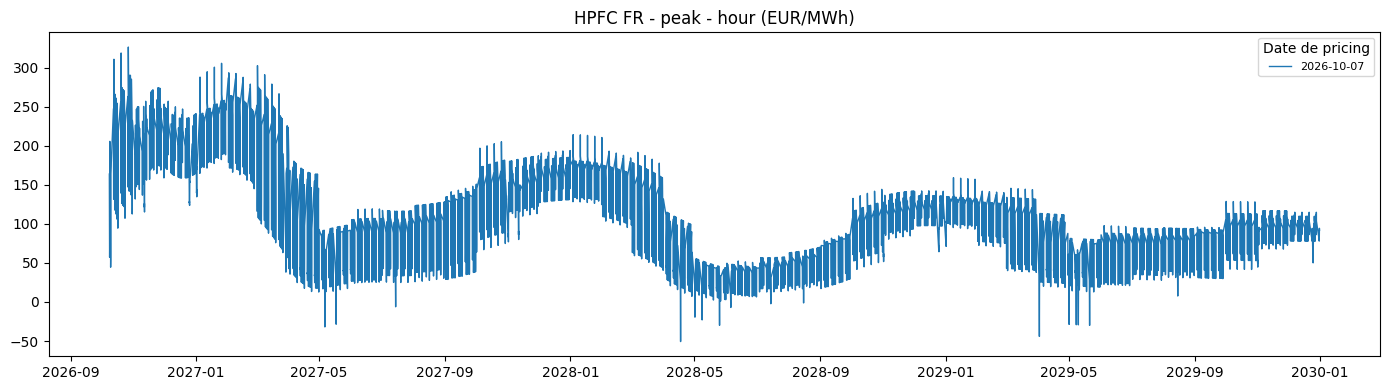

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 4))
series = result[["price"]] if "price" in result.columns else result
drawstyle = "steps-post" if GRANULARITY not in ("hour",) else "default"
for col in series.columns:
    label = str(pricing_dates[0]) if col == "price" else col
    ax.plot(series.index, series[col], lw=1, drawstyle=drawstyle, label=label)
ax.set_title(f"HPFC {MARKET} - {PROFILE} - {GRANULARITY} ({cfg.unit})")
ax.legend(title="Date de pricing", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Export

In [24]:
if OUTPUT is None:
    print("Pas d'export demandé (OUTPUT = None)")
else:
    out = Path(OUTPUT)
    if not out.is_absolute():
        out = REPO / out
    out.parent.mkdir(parents=True, exist_ok=True)
    export = result.copy()
    if isinstance(export.index, pd.DatetimeIndex) and export.index.tz is not None:
        # Excel ne gère pas les fuseaux : heure locale (ou UTC) écrite sans fuseau, indiquée dans l'en-tête
        export.index = export.index.tz_localize(None)
        export.index.name = f"{export.index.name} ({'Europe/Paris' if TIMEZONE == 'local' else 'UTC'})"
    if out.suffix == ".csv":
        export.to_csv(out)
    elif out.suffix == ".xlsx":
        try:
            import openpyxl  # noqa: F401
        except ImportError:
            raise ImportError("export Excel : installer openpyxl dans envir_lib "
                              "(../../envir_lib/bin/python -m pip install openpyxl)")
        export.to_excel(out, sheet_name="hpfc")
    elif out.suffix == ".parquet":
        result.to_parquet(out)
    else:
        raise ValueError("OUTPUT doit se terminer par .csv, .xlsx ou .parquet")
    print(f"Exporté : {out} ({len(export)} lignes)")

Exporté : /Users/clem/Documents/2-Coding/python/HPFC/power-hpfc/exports/test-data-peak.xlsx (10116 lignes)
